# Classical Finite-Difference Solver for the Burgers' Equation

## Objective

In this notebook, the one-dimensional viscous Burgers' equation is solved numerically using the finite-difference method and Forward Euler time integration.

The initial and boundary conditions are defined, and the velocity field is evolved over time to obtain a classical numerical reference solution.

The discrete first- and second-derivative operators are constructed and verified using matrix operations.

The nonlinear convection term is represented using the velocity-dependent diagonal operator, and the matrix-based formulation is compared with the direct finite-difference update.

Finally, the velocity profiles at selected time steps are plotted, and the numerical results are saved for use in subsequent tensor-train and quantum-circuit notebooks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#set parameters

L=1
nu=0.1

N=8
dt=0.001
T=0.5

dx= L/(N-1)
x=np.linspace(0,1,N)

u=np.sin(np.pi*x)


In [3]:
nt = int(T / dt)


times_to_save = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

solutions = {}
solutions[0.0] = u.copy()

for n in range(nt):

    # First derivative
    ux = np.zeros(N)
    ux[1:-1] = (u[2:] - u[:-2]) / (2 * dx)

    # Second derivative
    uxx = np.zeros(N)
    uxx[1:-1] = (u[2:] - 2*u[1:-1] + u[:-2]) / dx**2

    # Nonlinear term
    nonlinear = u * ux

    # Burgers equation
    ut = nu * uxx - nonlinear

    # Forward Euler
    u_new = u + dt * ut

    # Boundary conditions
    u_new[0] = 0.0
    u_new[-1] = 0.0

    # Move to next time step
    u = u_new

    t = (n + 1) * dt

    if np.isclose(t, times_to_save).any():
        solutions[round(t, 10)] = u.copy()


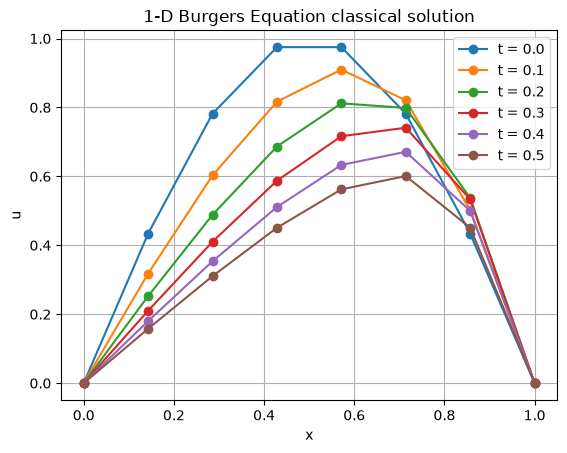

In [4]:
plt.figure()

for t, solution in solutions.items():
    plt.plot(x, solution, 'o-', label=f't = {t:.1f}')

plt.xlabel('x')
plt.ylabel('u')
plt.title('1-D Burgers Equation classical solution')
plt.legend()
plt.grid()

In [5]:
ux = np.zeros(N)
ux[1:-1] = (u[2:] - u[:-2]) / (2 * dx)


Dx = np.zeros((N, N))

for i in range(1, N-1):
    Dx[i, i-1] = -1 / (2*dx)
    Dx[i, i+1] =  1 / (2*dx)


ux_matrix = Dx @ u


print("Direct derivative:")
print(ux)

print("\nMatrix derivative:")
print(ux_matrix)

print("\nDifference:")
print(ux - ux_matrix)

Direct derivative:
[ 0.          1.08692563  1.02566904  0.88118796  0.52498895 -0.38989907
 -2.10284315  0.        ]

Matrix derivative:
[ 0.          1.08692563  1.02566904  0.88118796  0.52498895 -0.38989907
 -2.10284315  0.        ]

Difference:
[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.11022302e-16
  2.22044605e-16 -1.11022302e-16 -4.44089210e-16  0.00000000e+00]


In [6]:
uxx = np.zeros(N)
uxx[1:-1] = (u[2:] - 2*u[1:-1] + u[:-2]) / dx**2

Dxx = np.zeros((N, N))

for i in range(1, N-1):
    Dxx[i, i-1] = 1 / dx**2
    Dxx[i, i]   = -2 / dx**2
    Dxx[i, i+1] = 1 / dx**2


uxx_matrix = Dxx @ u

print("Direct second derivative:")
print(uxx)

print("\nMatrix second derivative:")
print(uxx_matrix)

print("\nDifference:")
print(uxx - uxx_matrix)

Direct second derivative:
[  0.          -0.24422601  -0.61336626  -1.40936884  -3.57741735
  -9.23101484 -14.75020237   0.        ]

Matrix second derivative:
[  0.          -0.24422601  -0.61336626  -1.40936884  -3.57741735
  -9.23101484 -14.75020237   0.        ]

Difference:
[ 0.00000000e+00  3.05311332e-16 -1.11022302e-15  1.99840144e-15
  3.99680289e-15 -3.55271368e-15  3.55271368e-15  0.00000000e+00]


In [7]:
Du = np.diag(u)

nonlinear = u * ux

nonlinear_matrix = Du @ ux_matrix


print("Direct nonlinear term:")
print(nonlinear)

print("\nMatrix nonlinear term:")
print(nonlinear_matrix)

print("\nDifference:")
print(nonlinear - nonlinear_matrix)



Direct nonlinear term:
[ 0.          0.1714812   0.3185217   0.39725318  0.29521082 -0.23425617
 -0.94821074  0.        ]

Matrix nonlinear term:
[ 0.          0.1714812   0.3185217   0.39725318  0.29521082 -0.23425617
 -0.94821074  0.        ]

Difference:
[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  5.55111512e-17
  1.11022302e-16 -5.55111512e-17 -2.22044605e-16  0.00000000e+00]


In [8]:
I = np.eye(N)

O = (I + nu * dt * Dxx- dt * Du @ Dx)

u_new = u + dt * (nu * uxx - nonlinear)

u_new_matrix= O @ u


print("Direct new velocity:")
print(u_new)

print("\nMatrix new velocity:")
print(u_new_matrix)

print("\nDifference:")
print(u_new - u_new_matrix)


Direct new velocity:
[0.         0.15757129 0.31017032 0.4502773  0.56166522 0.60012348
 0.45039162 0.        ]

Matrix new velocity:
[0.         0.15757129 0.31017032 0.4502773  0.56166522 0.60012348
 0.45039162 0.        ]

Difference:
[0. 0. 0. 0. 0. 0. 0. 0.]


In [9]:
u=np.sin(np.pi*x)

nt = int(T / dt)


times_to_save = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

solutions = {}
solutions[0.0] = u.copy()

for n in range(nt):

    Dx = np.zeros((N, N))

    for i in range(1, N-1):
        Dx[i, i-1] = -1 / (2*dx)
        Dx[i, i+1] =  1 / (2*dx)


    Dxx = np.zeros((N, N))

    for i in range(1, N-1):
        Dxx[i, i-1] = 1 / dx**2
        Dxx[i, i]   = -2 / dx**2
        Dxx[i, i+1] = 1 / dx**2


    Du = np.diag(u)


    I = np.eye(N)

    O = (I + nu * dt * Dxx- dt * Du @ Dx)

    u_new= O @ u

    u= u_new

    t = (n + 1) * dt
    
    if np.isclose(t, times_to_save).any():
        solutions[round(t, 10)] = u.copy()
    

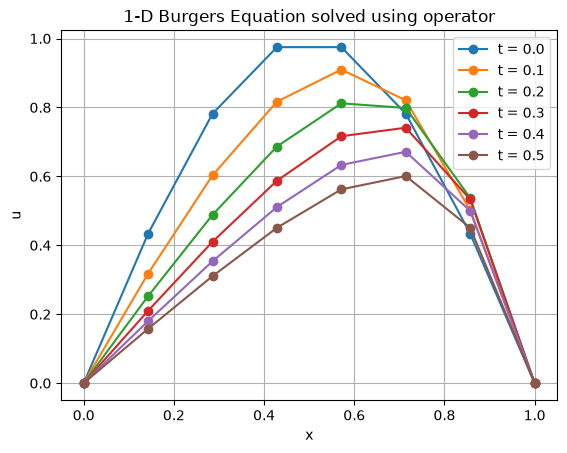

In [10]:
plt.figure()

for t, solution in solutions.items():
    plt.plot(x, solution, 'o-', label=f't = {t:.1f}')

plt.xlabel('x')
plt.ylabel('u')
plt.title('1-D Burgers Equation solved using operator')
plt.legend()
plt.grid()

In [11]:
times = np.array(sorted(solutions.keys()))

solution_array = np.array([
    solutions[t] for t in times
])

np.savez(
    "../results/data/burgers_classical_data.npz",
    x=x,
    times=times,
    solutions=solution_array
)

print("Saved classical Burgers data.")
print("Solution array shape:", solution_array.shape)

Saved classical Burgers data.
Solution array shape: (6, 8)
